# Week 3 · Part D — The clinical review figure

One 2×2 figure from `data/vitals_10k.csv` (10,000 synthetic patient records, generated for CDB601220), exported at 300 dpi.
Order of work: **inspect → clean (every rule logged with a count) → build the heatmap first → choose the scatter from it → finish and save.**

In [1]:
from __future__ import annotations
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.insert(0, str(Path.cwd()))
from vizlib import PALETTE, MARKERS, save_fig, style_defaults

style_defaults(dpi=100)
BLUE, VERM, GREEN = PALETTE["series"]; GREY = PALETTE["muted"]
ROOT = Path.cwd(); FIG = ROOT / "figs"; FIG.mkdir(exist_ok=True)
LOG: dict[str, str] = {}                 # the audit trail -> Part E item 3
pd.set_option("display.width", 200)

## Step 0 — look at the data before plotting anything

In [2]:
raw = pd.read_csv(ROOT / "data" / "vitals_10k.csv")
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  str    
 1   admit_date      10000 non-null  str    
 2   ward            10000 non-null  str    
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  str    
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), str(4)
memory usage: 1.2 MB


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.11,16.64,18.0,47.00,58.00,69.00,97.00
systolic,10000.0,137.66,22.60,92.0,119.00,128.00,160.00,199.00
diastolic,10000.0,79.63,13.13,45.0,69.00,78.00,90.00,125.00
map_mmhg,10000.0,98.97,15.83,65.3,85.70,94.30,113.70,149.70
heart_rate,10000.0,78.83,20.56,0.0,69.00,78.00,87.00,415.00
spo2,10000.0,96.72,2.24,81.0,96.00,97.00,98.00,100.00
bmi,10000.0,66.18,191.00,0.0,24.00,27.60,31.20,999.00
chol_mmol_l,10000.0,4.82,1.01,2.1,4.14,4.82,5.51,8.79
glucose_mmol_l,10000.0,6.55,1.15,5.1,5.70,6.30,7.10,13.90
los_days,10000.0,2.31,8.92,0.0,0.61,1.38,2.57,273.65


In [4]:
print(raw.ward.value_counts())
print("\nadmit_date, first 20:", raw.admit_date.head(20).tolist())
print("\nadmit_date formats:"); print(raw.admit_date.str.replace(r"[A-Za-z]{3}", "Mon", regex=True).str.replace(r"\d", "9", regex=True).value_counts())
print("\nsuspicious extremes:")
for col in ["heart_rate", "bmi", "spo2", "los_days", "risk_score"]:
    print(f"  {col:11s} min {raw[col].min():>8.2f}   max {raw[col].max():>8.2f}")
print("\nbmi == 999:", (raw.bmi == 999).sum(), "| bmi == 0:", (raw.bmi == 0).sum())
print("heart_rate < 30:", (raw.heart_rate < 30).sum(), "| heart_rate > 250:", (raw.heart_rate > 250).sum())

ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

admit_date, first 20: ['2026-01-19', '08-Mar-2026', '2026-02-26', '27/02/2026', '09/01/2026', '01-Apr-2026', '17-Apr-2026', '24-Mar-2026', '14-Apr-2026', '02-Jan-2026', '10/03/2026', '10/02/2026', '12-Apr-2026', '29/03/2026', '17-Apr-2026', '12/02/2026', '2026-03-28', '2026-02-03', '11-Apr-2026', '08/01/2026']

admit_date formats:
admit_date
9999-99-99     3382
99-Mon-9999    3365
99/99/9999     3253
Name: count, dtype: int64

suspicious extremes:
  heart_rate  min     0.00   max   415.00
  bmi         min     0.00   max   999.00
  spo2        min    81.00   max   100.00
  los_days    min     0.00   max   273.65
  risk_score  min     0.00   max     9.00

bmi =

**What the inspection shows (nine things wrong, none announced):**

| # | Problem | Evidence |
|---|---|---|
| 1 | `ward` has 12 spellings for 4 real wards | `General Medicine / general medicine / Gen Medicine`, `CARDIOLOGY / cardio / Cardiology`, `Day Surgery / Day-Surgery`, `Intensive Care / ICU / I.C.U / icu` |
| 2 | `admit_date` arrives in three text formats | `2026-01-19`, `08-Mar-2026`, `27/02/2026` |
| 3 | `bmi` has sentinel "missing" codes | max = 999 (402 rows), min = 0 (84 rows); mean = 66.2 |
| 4 | `heart_rate` has device faults | 8 readings of 0, 29 readings > 250 (max 415) |
| 5 | `map_mmhg` is **derived** from systolic & diastolic | its correlation with them is arithmetic |
| 6 | `risk_score` is a **ratio** (events per inpatient day) | its mean is not the overall rate |
| 7 | `los_days` is extremely right-skewed | median 1.4, mean 2.3, max 273.7 days |
| 8 | `spo2` has a hard ceiling at 100 | 3.0% of patients read exactly 100 |
| 9 | `systolic` is bimodal | two humps (≈ 120 and ≈ 163 mmHg) |

## Step 1 — clean it, and write down every rule

In [5]:
WARD_MAP = {"general medicine": "General Medicine", "gen medicine": "General Medicine",
            "cardiology": "Cardiology", "cardio": "Cardiology",
            "day surgery": "Day Surgery", "day-surgery": "Day Surgery",
            "intensive care": "ICU", "icu": "ICU", "i.c.u": "ICU"}

def clean(df: pd.DataFrame, drop_hr_faults: bool = True) -> pd.DataFrame:
    df = df.copy()
    LOG.clear()
    LOG["rows loaded"] = f"{len(df):,}"

    # 1 -- ward spellings: strip + lower, then map. Done BEFORE any groupby.
    n_raw = df.ward.nunique()
    df["ward_clean"] = df.ward.str.strip().str.lower().map(WARD_MAP)
    assert df.ward_clean.isna().sum() == 0 and df.ward_clean.nunique() == 4
    LOG["ward spellings conformed"] = f"{n_raw} spellings -> 4 wards; 0 unmapped; {(df.ward != df.ward_clean).sum():,} rows relabelled"

    # 2 -- dates: three formats. The slash format is dd/mm/yyyy: 1,933 slash dates have a first part > 12 and none has a second part > 12.
    s = df.admit_date.str.strip()
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    mon = pd.to_datetime(s, format="%d-%b-%Y", errors="coerce")
    dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    df["admit_dt"] = iso.fillna(mon).fillna(dmy)
    n_slash = s.str.contains("/").sum()
    parts = s[s.str.contains("/")].str.split("/", expand=True).astype(int)
    assert df.admit_dt.isna().sum() == 0 and (parts[1] <= 12).all() and (parts[0] > 12).sum() == 1933
    LOG["dates parsed"] = (f"3 formats, 0 unparsed; slash dates read as dd/mm ({(parts[0] > 12).sum():,} of {n_slash:,} have day > 12, none have month > 12; "
                           f"{((parts[0] <= 12) & (parts[1] <= 12)).sum():,} are ambiguous in isolation); range {df.admit_dt.min():%d %b %Y} to {df.admit_dt.max():%d %b %Y}")

    # 3 -- bmi sentinels 999 and 0 -> NaN
    sent = df.bmi.isin([0, 999])
    before = df.bmi.mean()
    df["bmi_clean"] = df.bmi.where(~sent)
    LOG["bmi sentinels removed"] = (f"{(df.bmi == 999).sum()} x 999 + {(df.bmi == 0).sum()} x 0 = {sent.sum()} values set to NaN; "
                                    f"mean {before:.2f} -> {df.bmi_clean.mean():.2f} kg/m2")

    # 4 -- heart-rate device faults: outside 30-250 bpm (0 = dropout, >250 = no human heart beats at 400)
    bad = (df.heart_rate < 30) | (df.heart_rate > 250)
    hr_before = df.heart_rate.mean()
    df["hr_clean"] = df.heart_rate.where(~bad) if drop_hr_faults else df.heart_rate.astype(float)
    if drop_hr_faults:
        LOG["heart-rate device faults removed"] = (f"rule: < 30 or > 250 bpm; n = {bad.sum()} ({(df.heart_rate > 250).sum()} above 250, {(df.heart_rate < 30).sum()} zeros); "
                                                   f"mean {hr_before:.1f} -> {df.hr_clean.mean():.1f} bpm; reading blanked, patient's other vitals kept")
    else:
        LOG["heart-rate device faults removed"] = "NOT applied (appendix version)"

    # 5 -- derived column
    assert np.abs(df.map_mmhg - (df.systolic + 2 * df.diastolic) / 3).max() < 0.06
    LOG["derived column excluded"] = "map_mmhg = (systolic + 2 x diastolic)/3 verified to +-0.05 mmHg; left out of heatmap"

    # 6 -- los_days = 0 cannot be drawn on a log axis
    LOG["los_days"] = f"{(df.los_days == 0).sum()} rows with 0 days excluded from the log-scale box plot only; {(df.los_days > 60).sum()} stays > 60 days kept (real tail)"
    return df

df = clean(raw)
for k, v in LOG.items(): print(f"{k:34s} {v}")

rows loaded                        10,000
ward spellings conformed           12 spellings -> 4 wards; 0 unmapped; 6,533 rows relabelled
dates parsed                       3 formats, 0 unparsed; slash dates read as dd/mm (1,933 of 3,253 have day > 12, none have month > 12; 1,320 are ambiguous in isolation); range 01 Jan 2026 to 30 Apr 2026
bmi sentinels removed              402 x 999 + 84 x 0 = 486 values set to NaN; mean 66.18 -> 27.35 kg/m2
heart-rate device faults removed   rule: < 30 or > 250 bpm; n = 37 (29 above 250, 8 zeros); mean 78.8 -> 78.0 bpm; reading blanked, patient's other vitals kept
derived column excluded            map_mmhg = (systolic + 2 x diastolic)/3 verified to +-0.05 mmHg; left out of heatmap
los_days                           2 rows with 0 days excluded from the log-scale box plot only; 18 stays > 60 days kept (real tail)


In [6]:
# demonstrations backing the log: how much each fault moves what we would report
print("ward counts after cleaning:"); print(df.ward_clean.value_counts())
print("\nheart rate:  raw mean %.2f / SD %.1f   ->   cleaned mean %.2f / SD %.1f" % (raw.heart_rate.mean(), raw.heart_rate.std(), df.hr_clean.mean(), df.hr_clean.std()))
print("bmi:         raw mean %.2f   ->   cleaned mean %.2f" % (raw.bmi.mean(), df.bmi_clean.mean()))
# risk_score is a ratio: mean of ratios != ratio of sums
df["events"] = df.risk_score * df.los_days
w = df[df.los_days > 0].groupby("ward_clean").apply(lambda g: pd.Series({"mean of risk_score": g.risk_score.mean(), "events / inpatient-days": g.events.sum() / g.los_days.sum()}), include_groups=False)
print("\nrisk_score: the mean of the column is not the rate:"); print(w.round(3))

ward counts after cleaning:
ward_clean
General Medicine    4018
Cardiology          2682
ICU                 1821
Day Surgery         1479
Name: count, dtype: int64

heart rate:  raw mean 78.83 / SD 20.6   ->   cleaned mean 78.05 / SD 13.0
bmi:         raw mean 66.18   ->   cleaned mean 27.35

risk_score: the mean of the column is not the rate:
                  mean of risk_score  events / inpatient-days
ward_clean                                                   
Cardiology                     0.912                    0.574
Day Surgery                    1.424                    0.398
General Medicine               1.031                    0.650
ICU                            1.381                    0.767


## Step 2 — build the heatmap (panel 4) first, and let it choose the scatter (panel 3)

In [7]:
COLS = ["age", "systolic", "diastolic", "hr_clean", "spo2", "bmi_clean", "chol_mmol_l", "glucose_mmol_l", "los_days"]
NICE = {"age": "age", "systolic": "systolic", "diastolic": "diastolic", "hr_clean": "heart rate", "spo2": "SpO2", "bmi_clean": "BMI",
        "chol_mmol_l": "cholesterol", "glucose_mmol_l": "glucose", "los_days": "stay (days)"}
rho = df[COLS].corr(method="spearman").rename(index=NICE, columns=NICE)
pear = df[COLS].corr().rename(index=NICE, columns=NICE)
iu = np.triu_indices(len(COLS), 1)
pairs = sorted(((rho.index[i], rho.columns[j], rho.values[i, j], pear.values[i, j]) for i, j in zip(*iu)), key=lambda t: -abs(t[2]))
print("strongest pairs (Spearman rho, Pearson r):")
for a, b, r1, r2 in pairs[:5]: print(f"  {a:12s} {b:12s} rho {r1:+.2f}   r {r2:+.2f}")
print("\nall other pairs: |rho| <=", round(max(abs(t[2]) for t in pairs[2:]), 2))

strongest pairs (Spearman rho, Pearson r):
  systolic     diastolic    rho +0.87   r +0.89
  age          cholesterol  rho +0.33   r +0.34
  SpO2         glucose      rho +0.02   r +0.02
  age          stay (days)  rho -0.02   r -0.02
  systolic     heart rate   rho +0.01   r +0.01

all other pairs: |rho| <= 0.02


The heatmap is a **screening tool, not a result**: two pairs stand out — systolic ↔ diastolic (ρ ≈ 0.87; both are the same pressure wave, so this is physiology rather than a discovery) and **age ↔ cholesterol (ρ ≈ 0.33)**, the only substantive pair — everything else is ≈ 0.
Panel 3 therefore plots **age vs cholesterol**.

## Step 3 — the figure

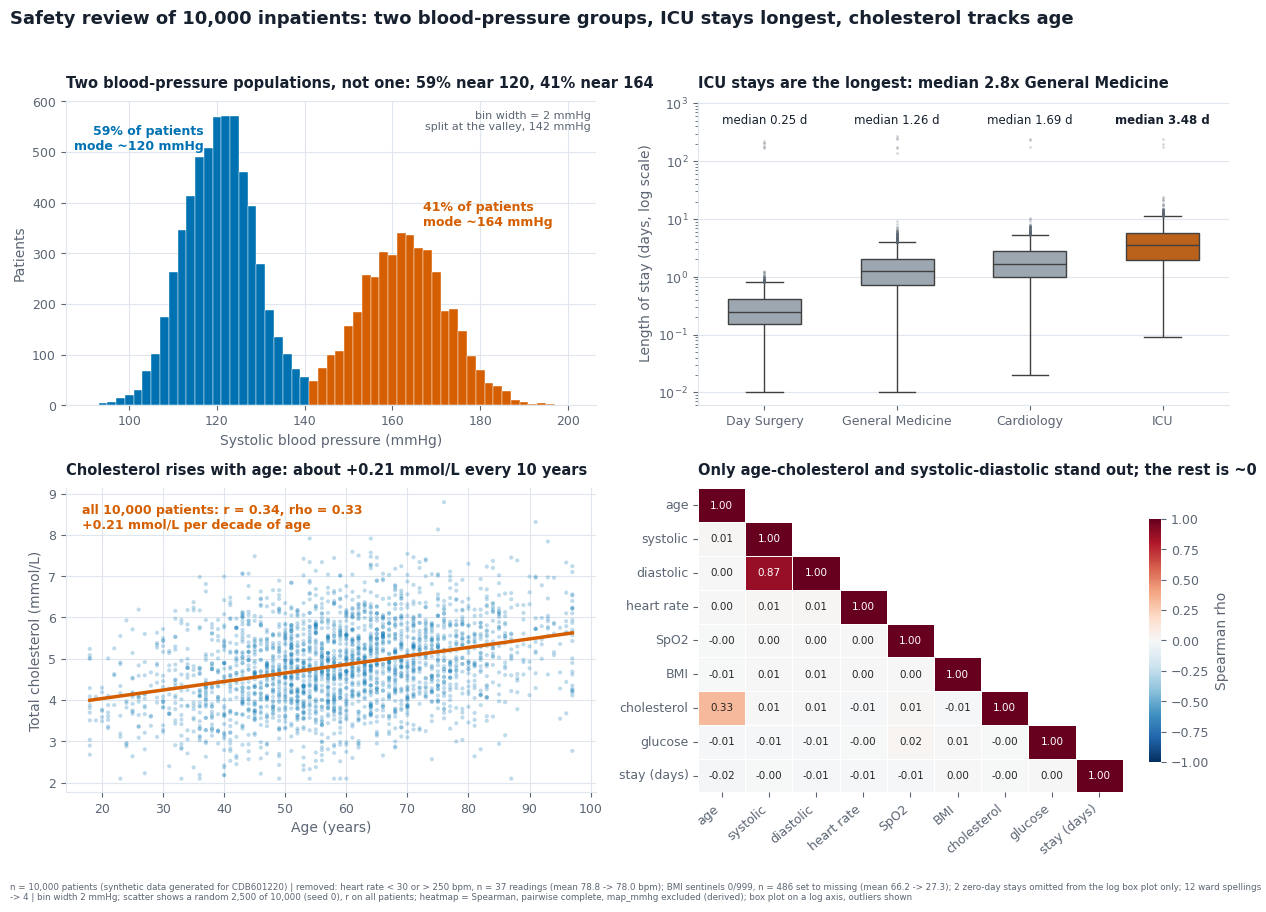

wrote /home/claude/run/figs/partD_figure.png


In [8]:
def build_figure(df, rho, n_hr_removed):
    fig, ax = plt.subplots(2, 2, figsize=(12.6, 8.8))

    # ---------------------------------------------------------- panel 1: distribution, bin width declared
    a = ax[0, 0]
    BW = 2                                                         # mmHg; data are whole numbers, so >= 1 is the honest minimum
    edges = np.arange(df.systolic.min() - 1, df.systolic.max() + BW + 1, BW)
    cnt, e = np.histogram(df.systolic, bins=edges)
    mid = (e[:-1] + e[1:]) / 2
    sm = np.convolve(cnt, np.ones(5) / 5, mode="same")
    valley = mid[(mid > 125) & (mid < 160)][sm[(mid > 125) & (mid < 160)].argmin()]
    colr = np.where(mid < valley, BLUE, VERM)
    a.bar(mid, cnt, width=BW, color=colr, edgecolor="white", linewidth=0.3)
    lo_share = (df.systolic < valley).mean()
    m1 = mid[mid < valley][sm[mid < valley].argmax()]; m2 = mid[mid >= valley][sm[mid >= valley].argmax()]      # modes of the 5-bin moving average
    a.text(m1 - 3, cnt.max() * 0.97, f"{lo_share:.0%} of patients\nmode ~{m1:.0f} mmHg", color=BLUE, ha="right", va="top", fontweight="bold", fontsize=9)
    a.text(m2 + 3, cnt[mid >= valley].max() * 1.02, f"{1 - lo_share:.0%} of patients\nmode ~{m2:.0f} mmHg", color=VERM, ha="left", va="bottom", fontweight="bold", fontsize=9)
    a.set_xlabel("Systolic blood pressure (mmHg)"); a.set_ylabel("Patients")
    a.set_title(f"Two blood-pressure populations, not one: {lo_share:.0%} near {m1:.0f}, {1 - lo_share:.0%} near {m2:.0f}", fontsize=10.5)
    a.text(0.99, 0.97, f"bin width = {BW} mmHg\nsplit at the valley, {valley:.0f} mmHg", transform=a.transAxes, ha="right", va="top", fontsize=8, color=PALETTE["ink_soft"])

    # ---------------------------------------------------------- panel 2: box plot by ward, log scale, sorted by median
    b = ax[0, 1]
    d2 = df[df.los_days > 0]
    order = d2.groupby("ward_clean").los_days.median().sort_values().index.tolist()
    med = d2.groupby("ward_clean").los_days.median()
    pal = {w: (VERM if w == order[-1] else GREY) for w in order}
    sns.boxplot(data=d2, x="ward_clean", y="los_days", order=order, palette=pal, hue="ward_clean", legend=False, ax=b,
                width=0.55, linewidth=1, flierprops=dict(marker="o", markersize=2, alpha=0.25, markerfacecolor=PALETTE["ink_soft"], markeredgecolor="none"))
    b.set_yscale("log")                                            # right-skewed: a linear axis collapses every box to a line
    for i, w in enumerate(order):
        b.text(i, d2.los_days.max() * 1.6, f"median {med[w]:.2f} d", ha="center", fontsize=8.5, color=PALETTE["ink"], fontweight="bold" if w == order[-1] else "normal")
    b.set_ylim(top=d2.los_days.max() * 4)
    b.set_xlabel(""); b.set_ylabel("Length of stay (days, log scale)")
    b.grid(axis="x", visible=False)
    ratio = med[order[-1]] / med["General Medicine"]
    b.set_title(f"{order[-1]} stays are the longest: median {ratio:.1f}x General Medicine", fontsize=10.5)

    # ---------------------------------------------------------- panel 3: the one pair the heatmap chose
    c = ax[1, 0]
    full = df[["age", "chol_mmol_l"]].dropna()
    samp = full.sample(2500, random_state=0)                       # subsample size declared in the note
    c.scatter(samp.age, samp.chol_mmol_l, s=9, alpha=0.25, color=BLUE, edgecolor="none", marker=MARKERS[0], rasterized=True)
    slope, icpt = np.polyfit(full.age, full.chol_mmol_l, 1)
    xs = np.array([full.age.min(), full.age.max()])
    c.plot(xs, slope * xs + icpt, color=VERM, lw=2.5)
    r_p = full.age.corr(full.chol_mmol_l); r_s = full.age.corr(full.chol_mmol_l, method="spearman")
    c.text(0.03, 0.95, f"all {len(full):,} patients: r = {r_p:.2f}, rho = {r_s:.2f}\n+{slope * 10:.2f} mmol/L per decade of age", transform=c.transAxes, va="top", fontsize=9, color=VERM, fontweight="bold")
    c.set_xlabel("Age (years)"); c.set_ylabel("Total cholesterol (mmol/L)")
    c.set_title(f"Cholesterol rises with age: about +{slope * 10:.2f} mmol/L every 10 years", fontsize=10.5)

    # ---------------------------------------------------------- panel 4: correlation heatmap to the Lecture-6 rules
    d = ax[1, 1]
    mask = np.triu(np.ones_like(rho, dtype=bool), k=1)
    sns.heatmap(rho, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7.5},
                linewidths=0.5, linecolor="white", square=False, cbar_kws={"shrink": 0.8, "label": "Spearman rho"}, ax=d)
    d.set_title("Only age-cholesterol and systolic-diastolic stand out; the rest is ~0", fontsize=10.5)
    d.grid(False); d.tick_params(axis="x", rotation=40)
    for lab in d.get_xticklabels(): lab.set_ha("right")

    fig.suptitle("Safety review of 10,000 inpatients: two blood-pressure groups, ICU stays longest, cholesterol tracks age",
                 x=0.01, ha="left", fontweight="bold", fontsize=13)
    for p in ax.flat:
        for sp in ("top", "right"): p.spines[sp].set_visible(False)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    return fig, dict(BW=BW, valley=valley, slope=slope, r=r_p, rho=r_s, order=order, med=med.to_dict(), lo_share=lo_share, m1=m1, m2=m2)

n_hr = int(df.hr_clean.isna().sum())
fig, info = build_figure(df, rho, n_hr)
note = (f"n = {len(df):,} patients (synthetic data generated for CDB601220) | removed: heart rate < 30 or > 250 bpm, n = {n_hr} readings (mean {raw.heart_rate.mean():.1f} -> {df.hr_clean.mean():.1f} bpm); "
        f"BMI sentinels 0/999, n = {int(df.bmi_clean.isna().sum())} set to missing (mean {raw.bmi.mean():.1f} -> {df.bmi_clean.mean():.1f}); 2 zero-day stays omitted from the log box plot only; "
        f"12 ward spellings -> 4 | bin width {info['BW']} mmHg; scatter shows a random 2,500 of {len(df):,} (seed 0), r on all patients; heatmap = Spearman, pairwise complete, map_mmhg excluded (derived); "
        f"box plot on a log axis, outliers shown")
fig.text(0.01, -0.012, note, fontsize=6.3, color=PALETTE["ink_soft"], ha="left", va="top", wrap=True)
out = FIG / "partD_figure.png"
fig.savefig(out, dpi=300, bbox_inches="tight", facecolor=PALETTE["surface"])        # save BEFORE show
plt.show()
print("wrote", out)

In [9]:
from PIL import Image
im = Image.open(FIG / "partD_figure.png"); print("exported figure:", im.size, "pixels ->", round(im.size[0] / 300, 1), "x", round(im.size[1] / 300, 1), "inches at 300 dpi")
print("\nvalley split:", info["valley"], "| modes:", info["m1"], info["m2"], "| age slope per decade: %.3f" % (info["slope"] * 10))
print("ward medians:", {k: round(v, 2) for k, v in info["med"].items()})

exported figure: (3789, 2736) pixels -> 12.6 x 9.1 inches at 300 dpi

valley split: 142.0 | modes: 120.0 164.0 | age slope per decade: 0.206
ward medians: {'Cardiology': 1.69, 'Day Surgery': 0.25, 'General Medicine': 1.26, 'ICU': 3.48}


## Step 4 — the ethics clause: the figure was also produced *without* the heart-rate exclusion (appendix)

In [10]:
df_all = clean(raw, drop_hr_faults=False)           # LOG now says "NOT applied"
rho_all = df_all[COLS].corr(method="spearman").rename(index=NICE, columns=NICE)
fig2, info2 = build_figure(df_all, rho_all, 0)
fig2.text(0.01, -0.012, "APPENDIX: identical figure with NO heart-rate exclusion (all 10,000 readings, incl. 0 and up to 415 bpm). Heart rate appears only in panel 4. Synthetic data, CDB601220.",
          fontsize=7, color=PALETTE["ink_soft"], ha="left", va="top")
fig2.savefig(FIG / "partD_figure_appendix_no_hr_exclusion.png", dpi=300, bbox_inches="tight", facecolor=PALETTE["surface"])
plt.close(fig2)

# symmetry test: does the exclusion change ANY conclusion?
diff = (rho - rho_all).abs()
hr = "heart rate"
print("largest change in any heatmap cell caused by the exclusion: %.3f" % diff.values.max(), "| in the heart-rate row/column: %.3f" % diff[hr].max())
print("heart-rate mean: all readings %.1f bpm -> after exclusion %.1f bpm (n removed = %d)" % (raw.heart_rate.mean(), df.hr_clean.mean(), n_hr))
print("heart-rate SD  : all readings %.1f -> after exclusion %.1f" % (raw.heart_rate.std(), df.hr_clean.std()))
df = clean(raw)    # restore the cleaned frame and the LOG
print("\nLOG restored:", list(LOG)[:3], "...")

largest change in any heatmap cell caused by the exclusion: 0.002 | in the heart-rate row/column: 0.002
heart-rate mean: all readings 78.8 bpm -> after exclusion 78.0 bpm (n removed = 37)
heart-rate SD  : all readings 20.6 -> after exclusion 13.0

LOG restored: ['rows loaded', 'ward spellings conformed', 'dates parsed'] ...


**Result of the symmetry test.** The exclusion moves the heart-rate mean from **78.8 to 78.0 bpm** and cuts its SD from **20.6 to 13.0**, but changes **no heatmap cell by more than 0.002** and alters none of the four panels' messages
(heart rate is correlated with nothing either way). The removal rule (< 30 or > 250 bpm) was fixed from physiology **before** looking at any correlation, and it would have been applied identically had it weakened my conclusion — so it is a cleaning rule, not an edit.

## Cleaning log (this is Part E, item 3)

In [11]:
for k, v in LOG.items(): print(f"{k:34s} {v}")

rows loaded                        10,000
ward spellings conformed           12 spellings -> 4 wards; 0 unmapped; 6,533 rows relabelled
dates parsed                       3 formats, 0 unparsed; slash dates read as dd/mm (1,933 of 3,253 have day > 12, none have month > 12; 1,320 are ambiguous in isolation); range 01 Jan 2026 to 30 Apr 2026
bmi sentinels removed              402 x 999 + 84 x 0 = 486 values set to NaN; mean 66.18 -> 27.35 kg/m2
heart-rate device faults removed   rule: < 30 or > 250 bpm; n = 37 (29 above 250, 8 zeros); mean 78.8 -> 78.0 bpm; reading blanked, patient's other vitals kept
derived column excluded            map_mmhg = (systolic + 2 x diastolic)/3 verified to +-0.05 mmHg; left out of heatmap
los_days                           2 rows with 0 days excluded from the log-scale box plot only; 18 stays > 60 days kept (real tail)


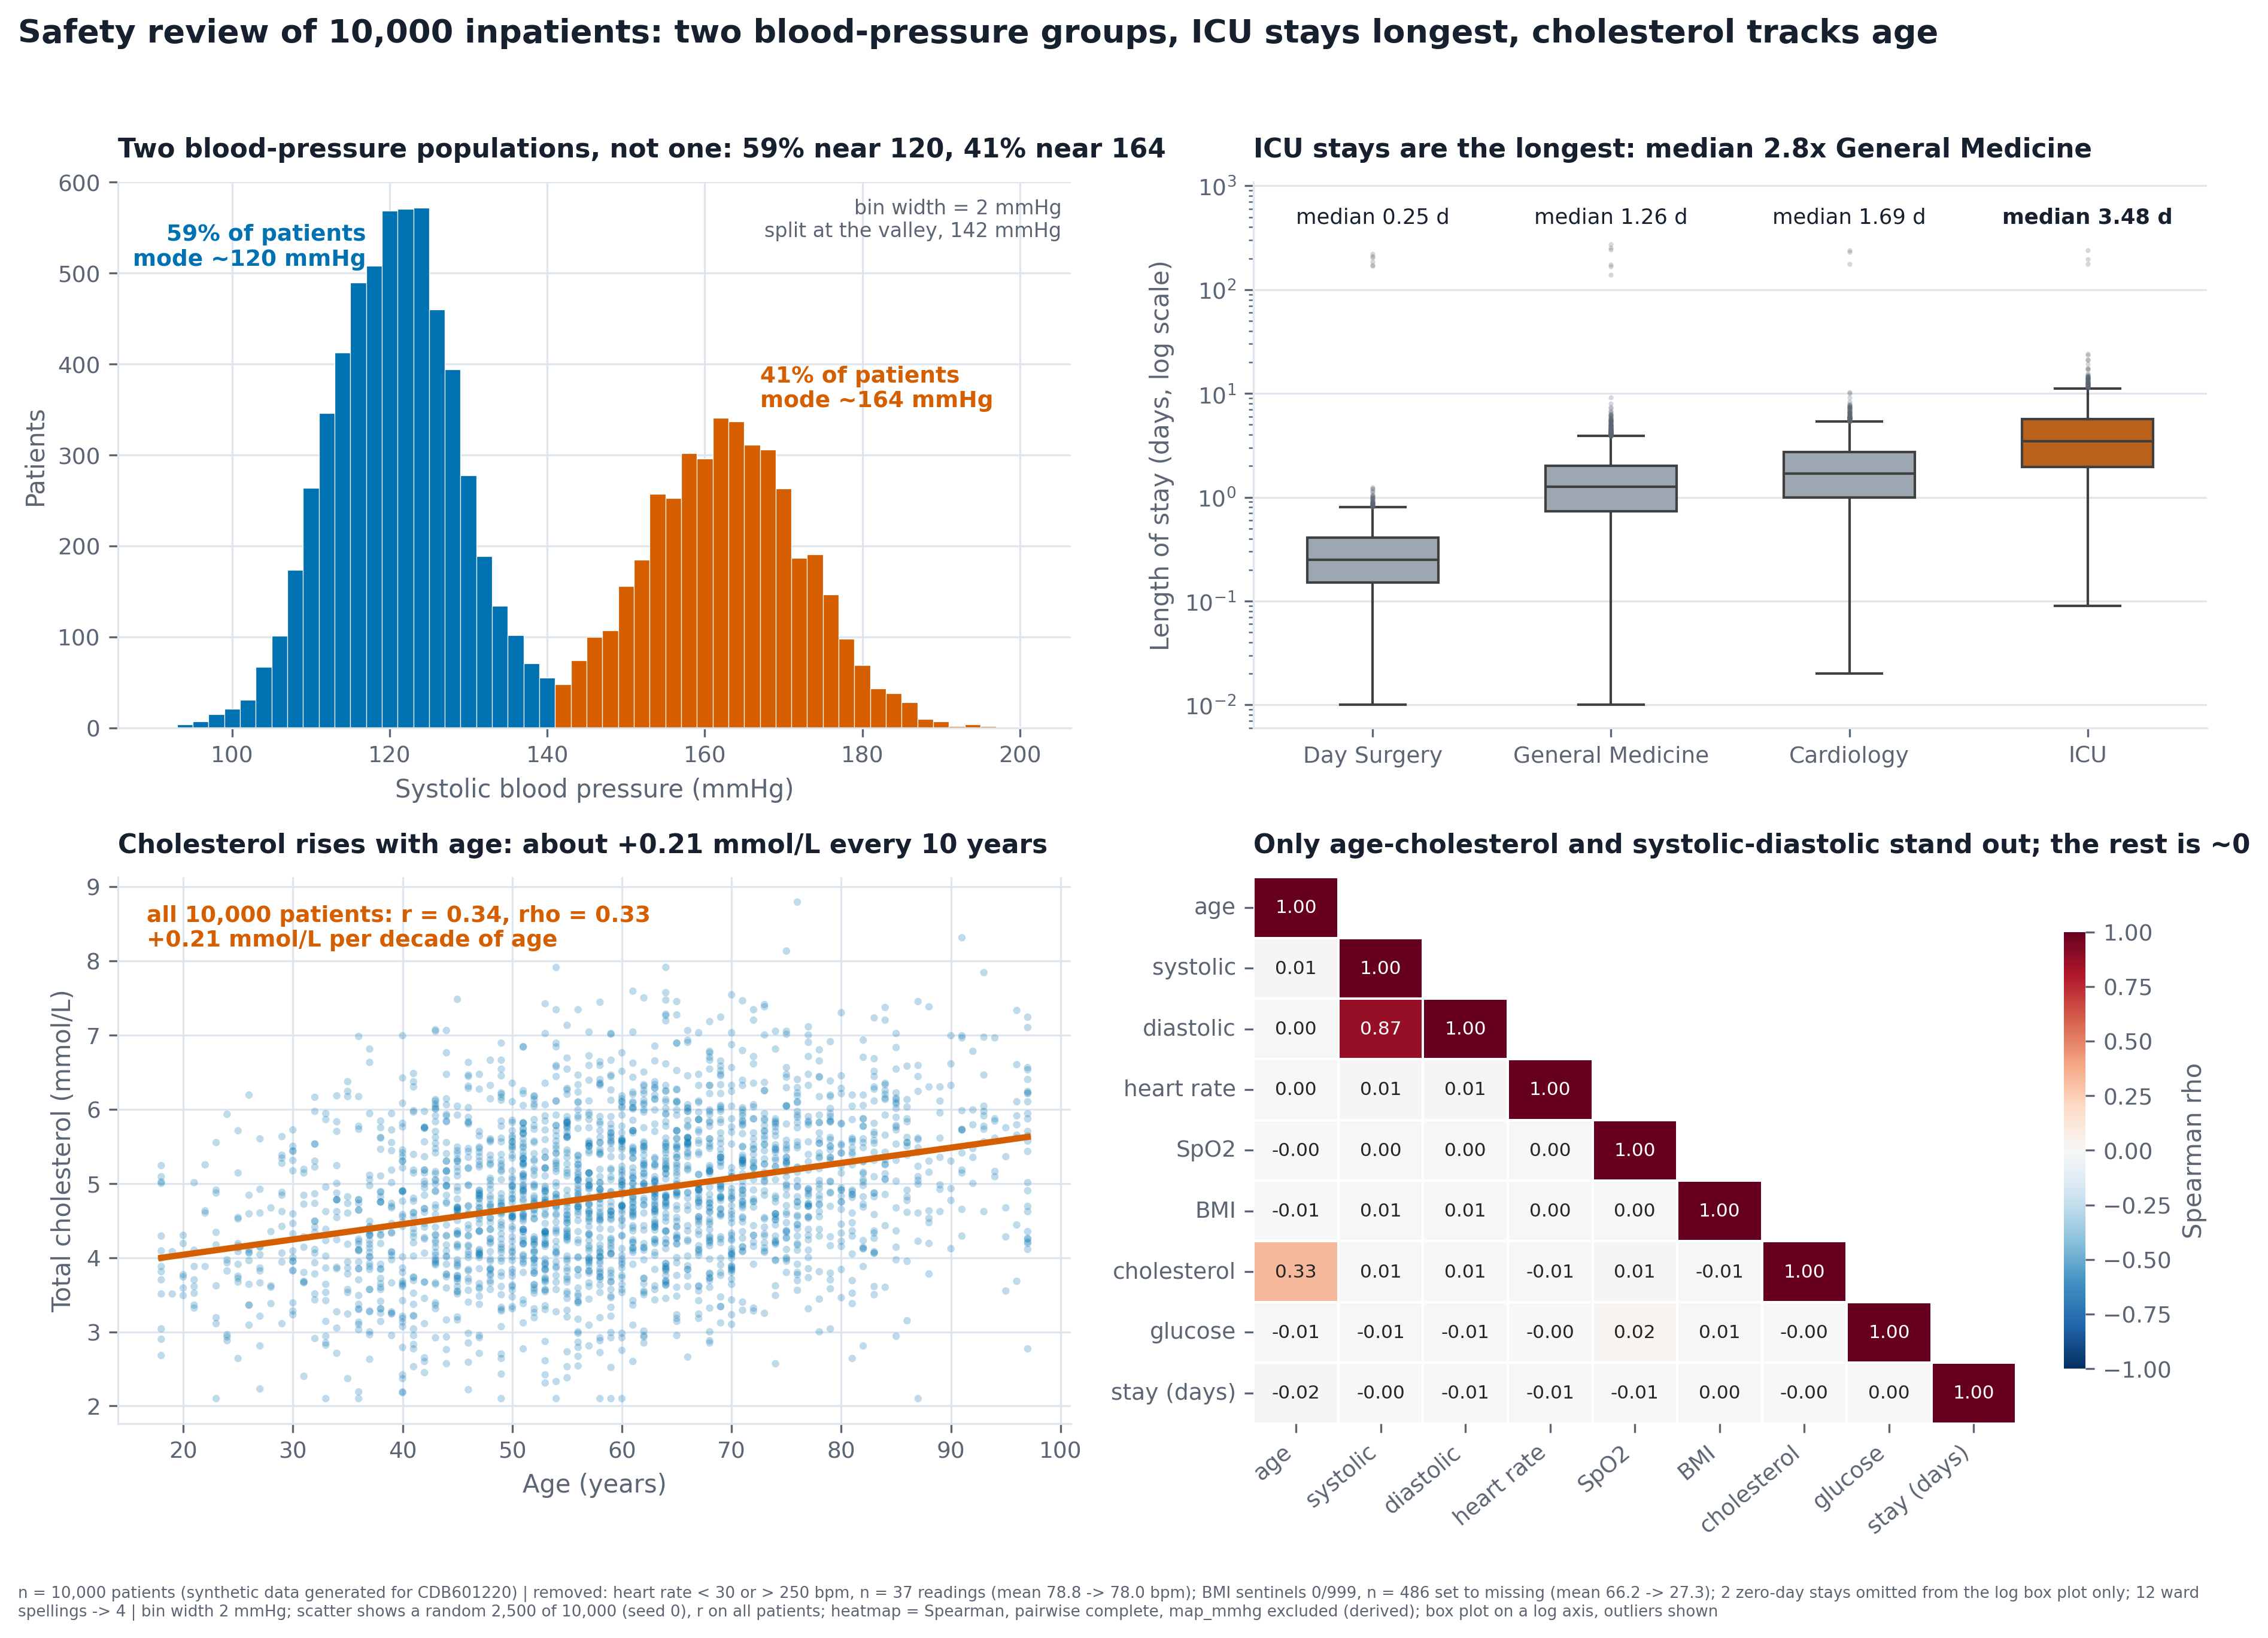

In [12]:
from IPython.display import Image as IPImage, display
display(IPImage(filename=str(FIG / "partD_figure.png"), width=1000))